# Confidence-Based Irradiance Overlay

Creates a two-layer overlay:
1. White pixels for areas above confidence threshold
2. Irradiance-based shading applied to white pixels

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

%matplotlib inline

In [ ]:
# Configuration
CONFIDENCE_THRESHOLD = 0.5  # Adjust this value (0.0 to 1.0)

# Paths - update for your image
IMAGE_NAME = 'simple_living_2'
BASE_PATH = Path(f'../rgb-x_output/batch_output/{IMAGE_NAME}')


confidence_path = BASE_PATH / f"{IMAGE_NAME}_wall_confidence.npy"
irradiance_path = BASE_PATH / f"{IMAGE_NAME}_irradiance.npy"
rgb_path = BASE_PATH / f"{IMAGE_NAME}.jpg"

In [30]:
# Load data
confidence = np.load(confidence_path)
irradiance = np.load(irradiance_path)
rgb_img = np.array(Image.open(rgb_path))

In [31]:
# Create confidence mask
mask = confidence > CONFIDENCE_THRESHOLD

# Layer 1: White pixels where confidence is high
white_layer = np.ones_like(rgb_img) * 255
white_layer[~mask] = 0  # Black elsewhere

# Layer 2: Apply irradiance shading to white pixels
# Irradiance is single channel, expand to RGB
if irradiance.ndim == 2:
    irradiance_rgb = np.stack([irradiance] * 3, axis=-1)
else:
    irradiance_rgb = irradiance

# Multiply white pixels by irradiance (creates shading effect)
shaded_layer = (white_layer * (1-irradiance_rgb)).astype(np.uint8)

# Blend with original image (optional - adjust alpha for transparency)
alpha = 0.6  # 0=original image, 1=full overlay
result = (rgb_img * (1 - alpha) + shaded_layer * alpha).astype(np.uint8)

# NEW (conditional replacement):
result = rgb_img.copy()
result[mask] = shaded_layer[mask]  # Replace only where confidence > threshold

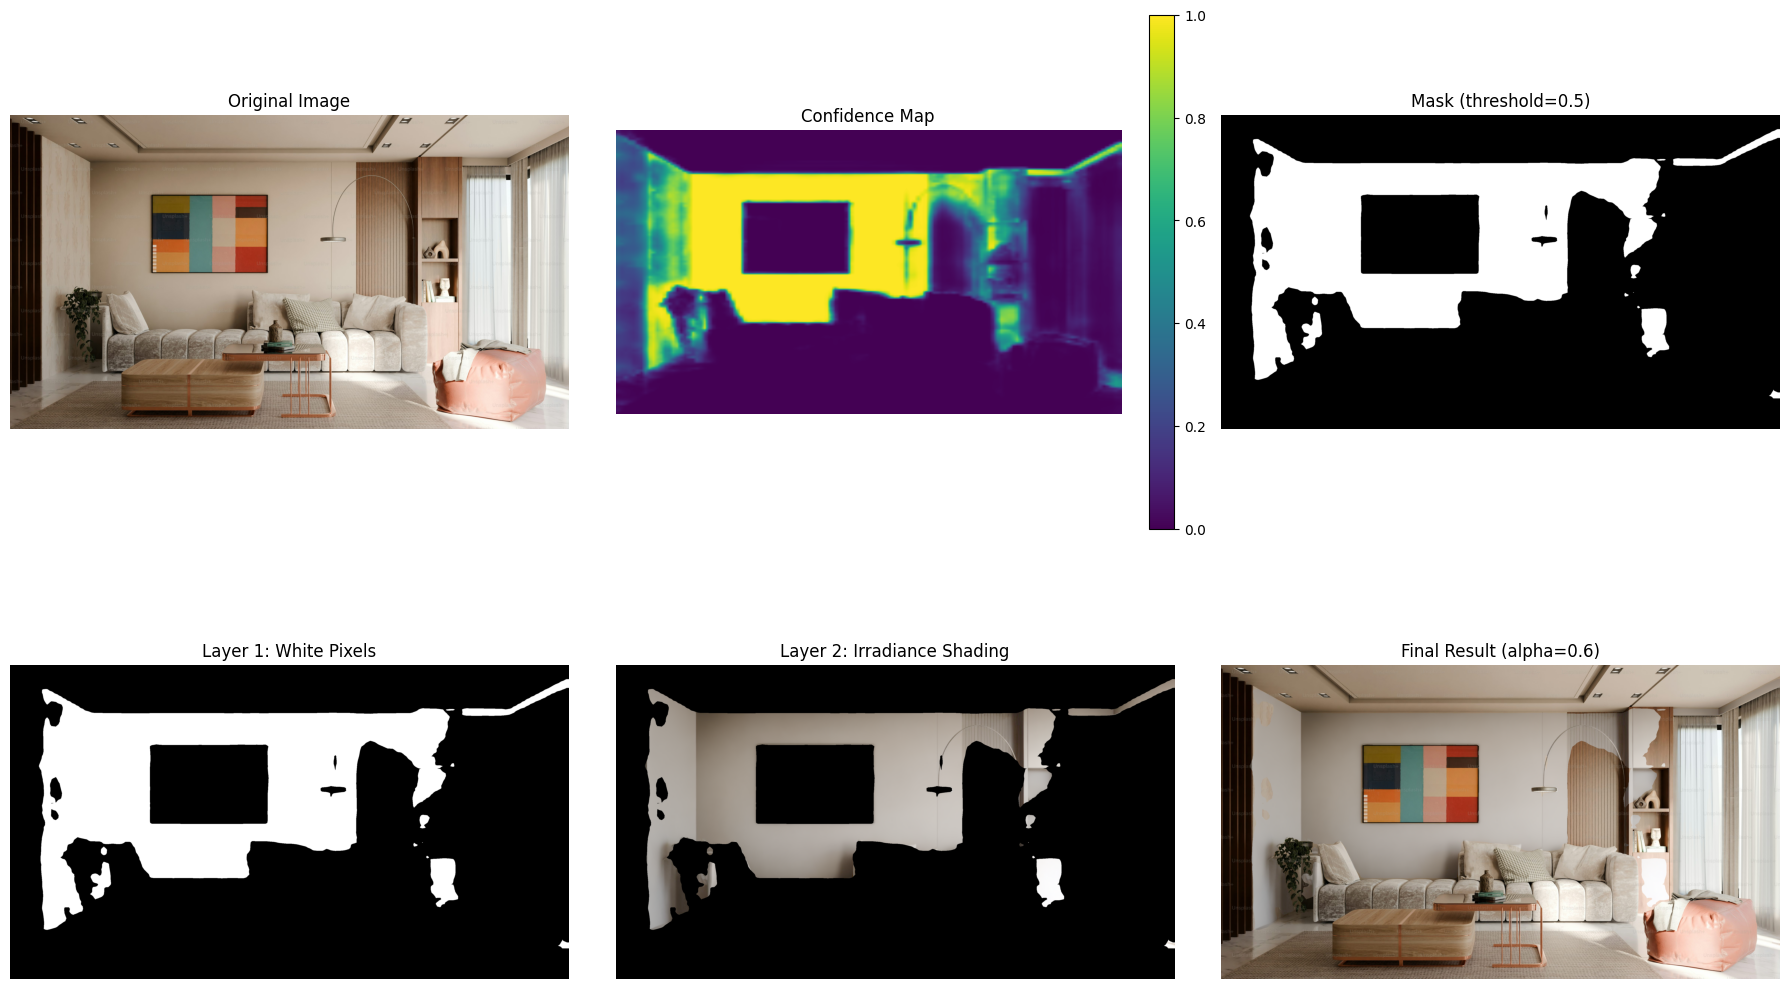

In [33]:
# Visualize
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

axes[0, 0].imshow(rgb_img)
axes[0, 0].set_title('Original Image')
axes[0, 0].axis('off')

axes[0, 1].imshow(confidence, cmap='viridis', vmin=0, vmax=1)
axes[0, 1].set_title(f'Confidence Map')
axes[0, 1].axis('off')
plt.colorbar(axes[0, 1].images[0], ax=axes[0, 1], fraction=0.046)

axes[0, 2].imshow(mask, cmap='gray')
axes[0, 2].set_title(f'Mask (threshold={CONFIDENCE_THRESHOLD})')
axes[0, 2].axis('off')

axes[1, 0].imshow(white_layer)
axes[1, 0].set_title('Layer 1: White Pixels')
axes[1, 0].axis('off')

axes[1, 1].imshow(shaded_layer)
axes[1, 1].set_title('Layer 2: Irradiance Shading')
axes[1, 1].axis('off')

axes[1, 2].imshow(result)
axes[1, 2].set_title(f'Final Result (alpha={alpha})')
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

In [20]:
def visualise_overlay(img, result):
    """Helper function to visualise original and result side by side."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    axes[0].imshow(img)
    axes[0].set_title('Original Image')
    axes[0].axis('off')
    
    axes[1].imshow(result)
    axes[1].set_title('Overlay Result')
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()

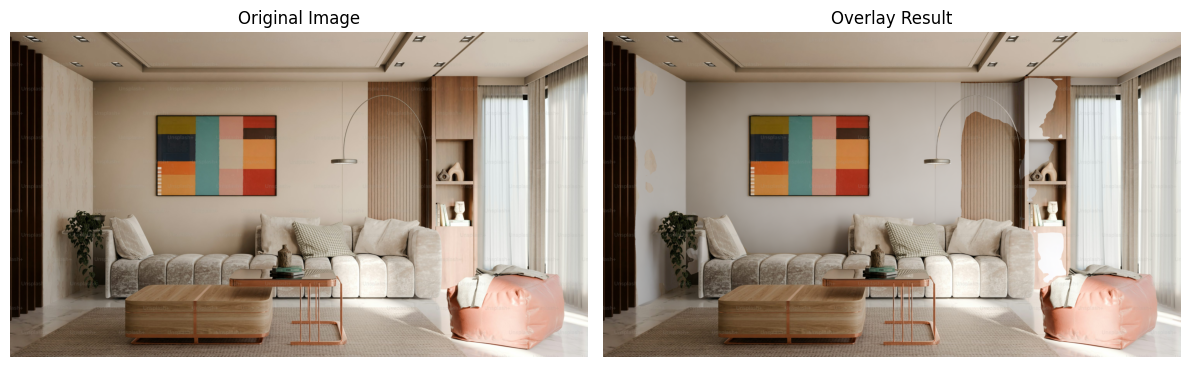

In [32]:
visualise_overlay(rgb_img, result)